<a href="https://colab.research.google.com/github/gostek198/podstawy-llm-lab-eiti-pw/blob/main/lab02/lab02_nanoGPT_LAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorium: Transformer od podstaw, nanoGPT i wstępnie wytrenowany model językowy

*Podstawy Wielkich Modeli Językowych z Zastosowaniami*

W tym laboratorium poznasz budowę modelu językowego typu **tylko-dekoder** (architektura GPT), sprawdzisz prostymi eksperymentami, że działa zgodnie z teorią, wytrenujesz mały model **nanoGPT** generujący tekst w stylu *Pana Tadeusza*, a na koniec wczytasz wagi większego modelu (~98 mln parametrów), wstępnie wytrenowanego na polskich tekstach z korpusu SpeakLeash, i zajrzysz do jego przebiegu treningu.

| Część | Zawartość |
|---|---|
| 0 | Przygotowanie środowiska i danych (tokenizacja na poziomie znaków) |
| 1A | Architektura Transformera: atencja przyczynowa, blok Transformer, model GPT (własna implementacja - dla chętnych). Ablacje **bez treningu** |
| 1B | Trenowanie nanoGPT (model znakowy) i ablacje **z treningiem**: co się dzieje, gdy usuniemy maskę, kodowanie pozycji, połączenia rezydualne, normalizację... |
| 2 | Wstępnie wytrenowany model GPT z tokenizatorem BPE: wczytanie wag, miary jakości (perplexity, BPC), dynamika uczenia, rozkład następnego tokenu |

### Zasady

- **Termin:** 2 tygodnie od zajęć. Oddajesz plik `.ipynb` **z wynikami wykonania** wszystkich komórek (*Środowisko wykonawcze → Uruchom wszystko*, potem *Plik → Pobierz*).
- **Zadanie** - uzupełnij kod w miejscach oznaczonych `# TODO` i usuń linię `raise NotImplementedError` (jeśli jest).
- **Zadania opcjonalne (dla chętnych)** - oznaczone literami (A, B, C, D). Nie są wymagane: jeśli ich nie zrobisz, notatnik i tak wykona się w całości, a testy tych zadań zostaną pominięte.
- **Test** - komórki z testami muszą wykonać się bez błędów. Nie modyfikuj ich.
- **Przewidywanie** - wpisz je **zanim** uruchomisz eksperyment. Liczy się uzasadnienie, nie trafność - błędne przewidywanie z dobrym wyjaśnieniem, dlaczego wynik okazał się inny, jest pełnowartościową odpowiedzią.
- **Odpowiedzi** pisz własnymi słowami, krótko (2-5 zdań), odwołując się do **swoich** wyników.
- Możesz korzystać z dokumentacji i narzędzi AI, ale musisz umieć wyjaśnić każdą linię swojego kodu - prowadzący może poprosić o krótką rozmowę o rozwiązaniu.
- Uruchom notatnik w Google Colab z akceleratorem GPU (*Środowisko wykonawcze → Zmień typ środowiska wykonawczego → T4 GPU*).

## Część 0. Przygotowanie

Wpisz swój numer albumu - posłuży jako ziarno generatora liczb losowych, dzięki czemu Twoje wyniki będą powtarzalne (i nieco inne niż u kolegów).

In [1]:
import math
import time
from dataclasses import dataclass, replace

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import Tensor

NR_ALBUMU = 325634      # <- wpisz swój numer albumu
SEED = NR_ALBUMU

torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__}, urządzenie: {device}")
if device.type != "cuda":
    print("UWAGA: brak GPU. W Colab: Środowisko wykonawcze -> Zmień typ środowiska wykonawczego -> T4 GPU")

PyTorch 2.14.1+cu130, urządzenie: cuda


### Dane i tokenizacja na poziomie znaków

Model będziemy trenować na tekście *Pana Tadeusza* z serwisu [Wolne Lektury](https://wolnelektury.pl) (domena publiczna), pobieranym ze zbioru przygotowanego na Hugging Face.

Zamiast tokenizatora BPE (np. polski GPT-2 ma słownik 51 200 tokenów) użyjemy **tokenizacji na poziomie znaków**: każdy znak jest osobnym tokenem, a słownik to zbiór wszystkich znaków występujących w tekście (niecałe 100). Dla małego modelu to rozsądny wybór: przy słowniku 51 200 tokenów same embeddingi tokenów i głowica wyjściowa miałyby ok. 26 mln parametrów ($2 \times 51\,200 \times 256$), czyli kilka razy więcej niż cały nasz model (ok. 3,2 mln). Kosztem są dłuższe sekwencje: to samo okno kontekstu obejmuje mniej tekstu.

In [2]:
from huggingface_hub import hf_hub_download

DATA_REPO = "jac99/llm-lab-teksty-pl"      # teksty z Wolnych Lektur (bez strony tytułowej i stopki)
path = hf_hub_download(DATA_REPO, "pan_tadeusz.txt", repo_type="dataset")
text = open(path, encoding="utf-8").read().strip()

print(f"Liczba znaków: {len(text):,}")
print(text[:500])

pan_tadeusz.txt:   0%|          | 0.00/481k [00:00<?, ?B/s]

Liczba znaków: 445,602
Księga pierwsza


Gospodarstwo

Powrót panicza — Spotkanie się pierwsze w pokoiku, drugie u stołu — Ważna Sędziego nauka o grzeczności — Podkomorzego uwagi polityczne nad modami — Początek sporu o Kusego i Sokoła — Żale Wojskiego — Ostatni Woźny Trybunału — Rzut oka na ówczesny stan polityczny Litwy i Europy

    Litwo! Ojczyzno moja! ty jesteś jak zdrowie;
Ile cię trzeba cenić, ten tylko się dowie,
Kto cię stracił. Dziś piękność twą w całej ozdobie
Widzę i opisuję, bo tęsknię po tobie.

    Pan


In [3]:
chars = sorted(set(text))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}     # znak -> identyfikator
itos = {i: ch for ch, i in stoi.items()}         # identyfikator -> znak


def encode(s: str) -> list[int]:
    return [stoi[c] for c in s]


def decode(ids: list[int]) -> str:
    return "".join(itos[i] for i in ids)


print(f"Rozmiar słownika: {vocab_size}")
print(repr("".join(chars)))
print(encode("Litwo!"), "->", decode(encode("Litwo!")))

Rozmiar słownika: 87
'\n !()*,-./128:;?ABCDEFGHIJKLMNOPRSTUVWZabcdefghijklmnopqrstuvwxyz«»ÓàæéóąĆćęŁłńŚśŹźŻż—…'
[27, 47, 58, 61, 53, 2] -> Litwo!


Dzielimy tekst na część treningową (pierwsze 90%) i walidacyjną (ostatnie 10%, czyli końcówka Księgi XII i Epilog).

Funkcja `get_batch` losuje `batch_size` fragmentów długości `context_length`. Sekwencja docelowa `y` to sekwencja wejściowa `x` przesunięta o jedną pozycję: model na pozycji $i$ ma przewidzieć znak $x_{i+1}$.

In [4]:
data = torch.tensor(encode(text), dtype=torch.long)
n_train = int(0.9 * len(data))
train_data, val_data = data[:n_train], data[n_train:]
print(f"Trening: {len(train_data):,} znaków, walidacja: {len(val_data):,} znaków")


def get_batch(split: str, batch_size: int, context_length: int) -> tuple[Tensor, Tensor]:
    # Zwraca parę tensorów (x, y) o wymiarach (batch_size, context_length)
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - context_length - 1, (batch_size,))
    x = torch.stack([d[i:i + context_length] for i in ix])
    y = torch.stack([d[i + 1:i + context_length + 1] for i in ix])
    return x.to(device), y.to(device)


x, y = get_batch("train", batch_size=2, context_length=24)
print("x:", repr(decode(x[0].tolist())))
print("y:", repr(decode(y[0].tolist())))

Trening: 401,041 znaków, walidacja: 44,561 znaków
x: 'rusaków,\nChoć lubił o ni'
y: 'usaków,\nChoć lubił o nic'


## Część 1A. Architektura Transformera

Oznaczenia wymiarów tensorów używane w komentarzach:
`B` - rozmiar wsadu, `T` - długość sekwencji, `C` - wymiar wektora cech (`emb_dim`), `h` - liczba głowic atencji, `d = C / h` - wymiar jednej głowicy, `V` - rozmiar słownika.

Konfigurację modelu opisuje klasa `GPTConfig`. Oprócz typowych hiperparametrów zawiera **flagi ablacji**, które pozwolą wyłączać poszczególne elementy architektury:

| Flaga | Domyślnie | Znaczenie |
|---|---|---|
| `causal` | `True` | maska przyczynowa w atencji |
| `pos_emb` | `True` | wyuczone embeddingi pozycyjne |
| `residual` | `True` | połączenia rezydualne w bloku |
| `layernorm` | `True` | normalizacja warstwy (*LayerNorm*) |
| `tie_weights` | `False` | współdzielenie wag embeddingów tokenów i głowicy wyjściowej |

In [5]:
@dataclass
class GPTConfig:
    vocab_size: int = vocab_size
    context_length: int = 128     # maksymalna długość sekwencji (okno kontekstu)
    emb_dim: int = 256            # C
    n_heads: int = 4              # h
    n_layers: int = 4             # liczba bloków Transformer
    ff_mult: int = 4              # rozmiar warstwy ukrytej FF = ff_mult * C
    dropout: float = 0.1
    bias: bool = True             # obciążenia w warstwach liniowych
    # Flagi ablacji
    causal: bool = True
    pos_emb: bool = True
    residual: bool = True
    layernorm: bool = True
    tie_weights: bool = False


print(GPTConfig())

GPTConfig(vocab_size=87, context_length=128, emb_dim=256, n_heads=4, n_layers=4, ff_mult=4, dropout=0.1, bias=True, causal=True, pos_emb=True, residual=True, layernorm=True, tie_weights=False)


### 1.1 Budowa modelu GPT

**Wielogłowicowa atencja przyczynowa.** Dla sekwencji wektorów cech $X \in \mathbb{R}^{T \times C}$ wyznaczamy zapytania, klucze i wartości:
$$Q = XW_Q, \quad K = XW_K, \quad V = XW_V .$$
Każdy z tensorów dzielimy na $h$ głowic o wymiarze $d = C/h$. Dla każdej głowicy:
$$\mathrm{Attention}(Q, K, V) = \mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d}} + M\right)V, \qquad M_{ij} = \begin{cases} 0 & j \le i \\ -\infty & j > i \end{cases}$$
Macierz $M$ to **maska przyczynowa**: element na pozycji $i$ nie może korzystać z elementów na późniejszych pozycjach. Wyniki głowic łączymy (konkatenacja) i przepuszczamy przez projekcję wyjściową $W_O$. W implementacji trzy projekcje $W_Q, W_K, W_V$ są połączone w jedną warstwę liniową `qkv` o wyjściu `3*C` (w tej kolejności: Q, K, V) - tak samo jak w `nn.MultiheadAttention` w PyTorch.

**Blok Transformer** składa się z atencji, bloku w pełni połączonego (*feed-forward*, FF: dwie warstwy liniowe z nieliniowością GELU), dwóch normalizacji i dwóch połączeń rezydualnych. Istnieją dwa warianty położenia normalizacji:

$$
\begin{array}{|l|l|l|}
\hline
\textbf{Wariant} & \textbf{Podwarstwa atencji} & \textbf{Podwarstwa FF} \\
\hline
\text{pre-LN (GPT-2 i nowsze)} & x \leftarrow x + \mathrm{Attn}(\mathrm{LN}_1(x)) & x \leftarrow x + \mathrm{FF}(\mathrm{LN}_2(x)) \\
\hline
\text{post-LN (oryginalny Transformer, GPT-1)} & x \leftarrow \mathrm{LN}_1(x + \mathrm{Attn}(x)) & x \leftarrow \mathrm{LN}_2(x + \mathrm{FF}(x)) \\
\hline
\end{array}
$$

W notatniku zaimplementowano tylko nowszy wariant **pre-LN**: ścieżka rezydualna $x \to x + \dots$ przechodzi przez cały model bez normalizacji, dzięki czemu gradient płynie bezpośrednio do wszystkich warstw, a trening głębokich modeli jest stabilny nawet bez rozgrzewki współczynnika uczenia (dlatego używają go GPT-2 i nowsze modele).

Bez połączeń rezydualnych (`residual=False`) wyrażenie $x + \mathrm{Sub}(\cdot)$ zastępujemy samym $\mathrm{Sub}(\cdot)$; bez normalizacji (`layernorm=False`) warstwy LN zastępujemy identycznością.

**Model GPT** składa się z:
- słownika embeddingów tokenów `tok_emb` i (opcjonalnie) embeddingów pozycyjnych `pos_emb` - wektory reprezentujące token i pozycję są **sumowane**,
- `n_layers` bloków Transformer,
- końcowej normalizacji `final_norm`,
- głowicy `head` - warstwy liniowej zwracającej dla każdej pozycji logity rozkładu prawdopodobieństwa następnego tokenu, `(B, T, V)`.

Inicjalizacja wag jest taka jak w GPT-2: rozkład normalny o odchyleniu 0,02, a dla projekcji wyjściowych podwarstw dodatkowo przeskalowany przez $1/\sqrt{2L}$.

Gotowa implementacja jest w komórce poniżej (kliknij ją dwukrotnie, aby zobaczyć kod). Warto ją przeczytać i porównać ze wzorami powyżej.

</b> Rysunki architektury - po lewej wariant z artykułu
(<b>post-LN</b>), po prawej ten zaimplementowany w notatniku (<b>pre-LN</b>).

<table>
<tr>
<td align="center"><b>Oryginalny Transformer (post-LN)</b><br><i>Attention Is All You Need</i>,<br>na czerwono przekreślone części nieużywane w modelu tylko-dekoder</td>
<td align="center"><b>Model z tego notatnika (pre-LN)</b><br>architektura klasy <code>GPTModel</code></td>
</tr>
<tr>
<td align="center">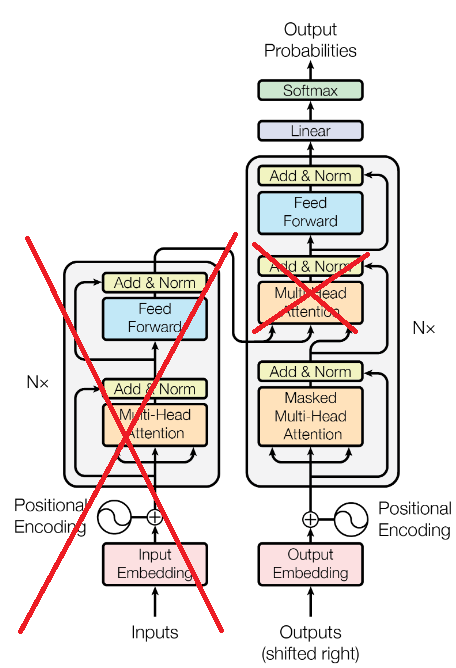</td>
<td align="center">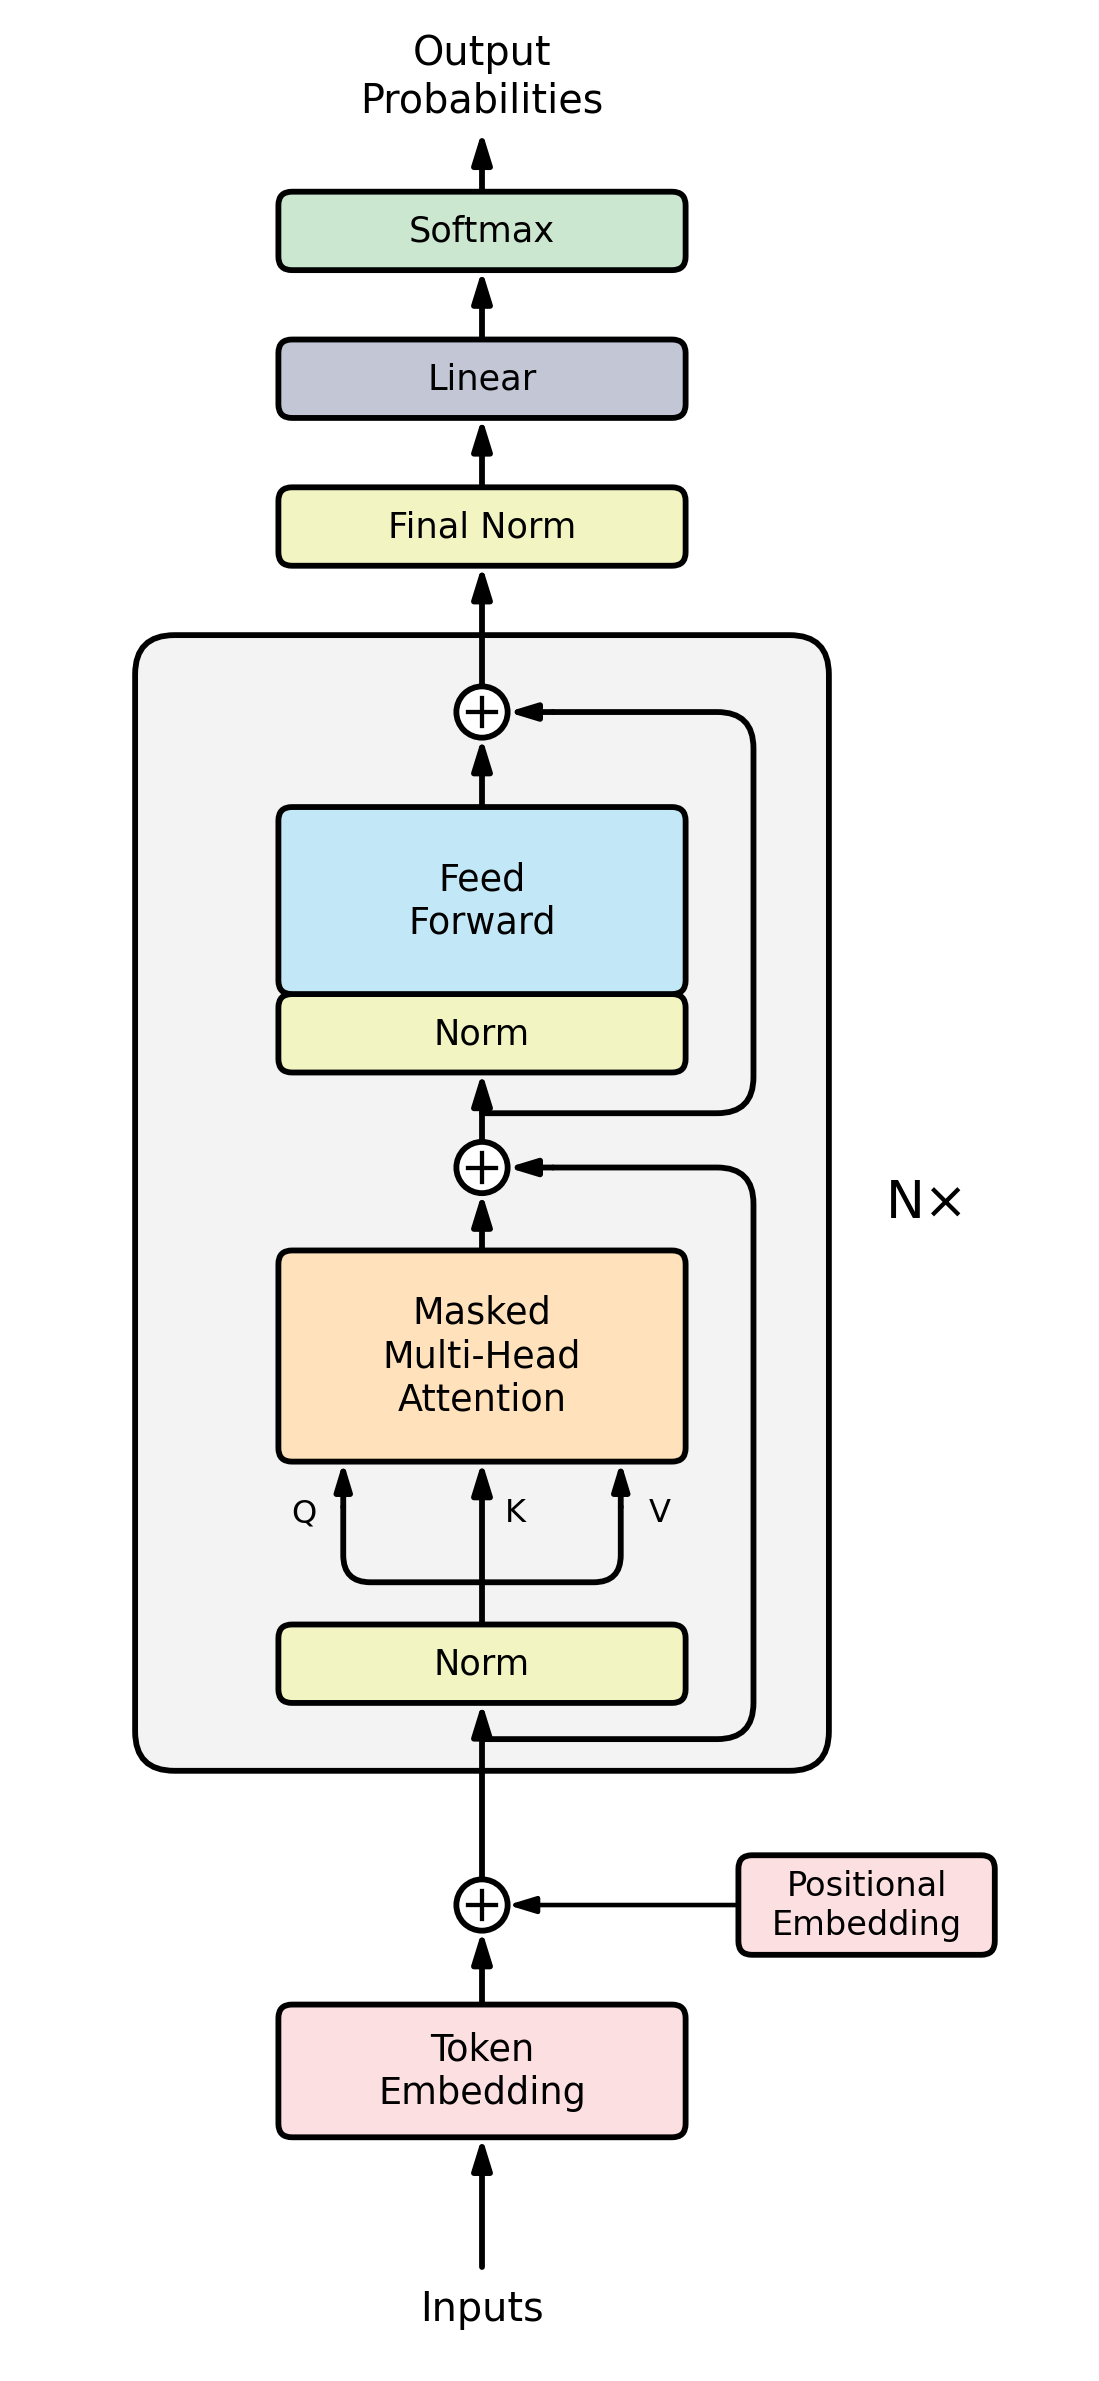</td>
</tr>
</table>

**Co porównać na obu rysunkach.** W wariancie **post-LN** (po lewej) normalizacja jest **po** podwarstwie i razem z dodaniem rezyduum tworzy jeden blok `Add & Norm`. W wariancie **pre-LN** (po prawej) `Norm` jest **przed** podwarstwą, a dodanie rezyduum ($\oplus$) następuje **po** niej - dzięki temu ścieżka rezydualna przechodzi przez cały model bez normalizacji (por. tabela powyżej). Stąd bierze się też `Final Norm` przed głowicą, której w post-LN nie ma.

Po prawej nie ma kodera ani cross-atencji (w oryginale przekreślone na czerwono), a zamiast kodowania sinusoidalnego jest **wyuczony** `Positional Embedding`, zgodnie z implementacją (`nn.Embedding(context_length, emb_dim)`).

Pozostałe bloki odpowiadają klasom z komórki poniżej: `Token Embedding` i `Positional Embedding` to `tok_emb` i `pos_emb` (ich wektory są **sumowane**), szary blok powtarzany $N$ = `n_layers` razy to `TransformerBlock`, `Masked Multi-Head Attention` to `CausalSelfAttention`, `Feed Forward` to `FeedForward`, a `Linear` to głowica `head`. Do atencji wchodzą **trzy** strzałki $Q$, $K$, $V$ z jednej linii, bo w samo-atencji wszystkie trzy powstają z tego samego wejścia - w kodzie to jedna warstwa `qkv` o wyjściu `3*C`, dzielona przez `split`. Dwa osobne źródła ($K$, $V$ z kodera) występują tylko w cross-atencji, której tu nie ma.

In [6]:
# @title Gotowa implementacja modelu GPT (kliknij dwukrotnie, aby zobaczyć kod)

class CausalSelfAttention(nn.Module):
    def __init__(self, cfg: GPTConfig):
        super().__init__()
        assert cfg.emb_dim % cfg.n_heads == 0
        self.n_heads = cfg.n_heads
        self.head_dim = cfg.emb_dim // cfg.n_heads
        self.causal = cfg.causal
        self.qkv = nn.Linear(cfg.emb_dim, 3 * cfg.emb_dim, bias=cfg.bias)   # W_Q, W_K, W_V
        self.proj = nn.Linear(cfg.emb_dim, cfg.emb_dim, bias=cfg.bias)      # W_O
        self.attn_dropout = nn.Dropout(cfg.dropout)
        self.resid_dropout = nn.Dropout(cfg.dropout)
        # Macierz dolnotrójkątna: mask[i, j] = True, gdy pozycja i może "widzieć" pozycję j
        mask = torch.tril(torch.ones(cfg.context_length, cfg.context_length, dtype=torch.bool))
        self.register_buffer("mask", mask, persistent=False)
        self.dropout = cfg.dropout
        self.use_sdpa = False      # True: szybka, gotowa implementacja PyTorch (używana w części 2)

    def _forward_sdpa(self, x: Tensor) -> Tensor:
        # To samo co forward, ale z F.scaled_dot_product_attention (szybciej, mniej pamięci).
        B, T, C = x.shape
        q, k, v = (t.view(B, T, self.n_heads, self.head_dim).transpose(1, 2) for t in self.qkv(x).split(C, dim=-1))
        y = F.scaled_dot_product_attention(q, k, v, is_causal=self.causal,
                                           dropout_p=self.dropout if self.training else 0.0)
        return self.resid_dropout(self.proj(y.transpose(1, 2).reshape(B, T, C)))

    def forward(self, x: Tensor, return_attn: bool = False):
        # x: (B, T, C)
        if self.use_sdpa and not return_attn:
            return self._forward_sdpa(x)
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=-1)                              # 3 x (B, T, C)
        q = q.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)       # (B, h, T, d)
        k = k.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)

        scores = q @ k.transpose(-2, -1) / math.sqrt(self.head_dim)         # (B, h, T, T)
        if self.causal:
            scores = scores.masked_fill(~self.mask[:T, :T], float("-inf"))
        att = torch.softmax(scores, dim=-1)                                 # (B, h, T, T)

        y = self.attn_dropout(att) @ v                                      # (B, h, T, d)
        y = y.transpose(1, 2).contiguous().view(B, T, C)                    # (B, T, C)
        y = self.resid_dropout(self.proj(y))
        return (y, att) if return_attn else y


class FeedForward(nn.Module):
    def __init__(self, cfg: GPTConfig):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(cfg.emb_dim, cfg.ff_mult * cfg.emb_dim, bias=cfg.bias),
            nn.GELU(),
            nn.Linear(cfg.ff_mult * cfg.emb_dim, cfg.emb_dim, bias=cfg.bias),
            nn.Dropout(cfg.dropout),
        )

    def forward(self, x: Tensor) -> Tensor:
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, cfg: GPTConfig):
        super().__init__()
        self.attn = CausalSelfAttention(cfg)
        self.ff = FeedForward(cfg)
        self.norm1 = nn.LayerNorm(cfg.emb_dim) if cfg.layernorm else nn.Identity()
        self.norm2 = nn.LayerNorm(cfg.emb_dim) if cfg.layernorm else nn.Identity()
        self.residual = cfg.residual

    def forward(self, x: Tensor) -> Tensor:
        # x: (B, T, C) -> (B, T, C); wariant pre-LN
        h = self.attn(self.norm1(x))
        x = x + h if self.residual else h
        h = self.ff(self.norm2(x))
        x = x + h if self.residual else h
        return x


class GPTModel(nn.Module):
    def __init__(self, cfg: GPTConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.emb_dim)
        self.pos_emb = nn.Embedding(cfg.context_length, cfg.emb_dim) if cfg.pos_emb else None
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([TransformerBlock(cfg) for _ in range(cfg.n_layers)])
        self.final_norm = nn.LayerNorm(cfg.emb_dim) if cfg.layernorm else nn.Identity()
        self.head = nn.Linear(cfg.emb_dim, cfg.vocab_size, bias=False)
        if cfg.tie_weights:
            self.head.weight = self.tok_emb.weight      # współdzielone wagi

        self.apply(self._init_weights)
        for name, p in self.named_parameters():
            if name.endswith("attn.proj.weight") or name.endswith("ff.net.2.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layers))

    @staticmethod
    def _init_weights(m: nn.Module):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def set_sdpa(self, enabled: bool = True) -> "GPTModel":
        """Przełącza wszystkie bloki na szybką implementację atencji (część 2)."""
        for block in self.blocks:
            block.attn.use_sdpa = enabled
        return self

    def forward(self, idx: Tensor) -> Tensor:
        # idx: (B, T) identyfikatory tokenów -> logity (B, T, V)
        B, T = idx.shape
        assert T <= self.cfg.context_length, "Sekwencja dłuższa niż okno kontekstu"
        x = self.tok_emb(idx)                                               # (B, T, C)
        if self.pos_emb is not None:
            x = x + self.pos_emb(torch.arange(T, device=idx.device))        # (T, C) - broadcast po B
        x = self.drop(x)
        for block in self.blocks:
            x = block(x)
        x = self.final_norm(x)
        return self.head(x)                                                 # (B, T, V)


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters())

In [7]:
model = GPTModel(GPTConfig())
print(model)
print(f"Liczba parametrów: {count_params(model):,}")

GPTModel(
  (tok_emb): Embedding(87, 256)
  (pos_emb): Embedding(128, 256)
  (drop): Dropout(p=0.1, inplace=False)
  (blocks): ModuleList(
    (0-3): 4 x TransformerBlock(
      (attn): CausalSelfAttention(
        (qkv): Linear(in_features=256, out_features=768, bias=True)
        (proj): Linear(in_features=256, out_features=256, bias=True)
        (attn_dropout): Dropout(p=0.1, inplace=False)
        (resid_dropout): Dropout(p=0.1, inplace=False)
      )
      (ff): FeedForward(
        (net): Sequential(
          (0): Linear(in_features=256, out_features=1024, bias=True)
          (1): GELU(approximate='none')
          (2): Linear(in_features=1024, out_features=256, bias=True)
          (3): Dropout(p=0.1, inplace=False)
        )
      )
      (norm1): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
      (norm2): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
    )
  )
  (final_norm): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=T

**Pytanie 1.1.** Po co w atencji dzielimy iloczyny skalarne przez $\sqrt{d}$? Co stałoby się z rozkładem wag atencji (i gradientami) dla dużego $d$ bez tego skalowania?

**Odpowiedź:** wartosc d okresla dlugosc wektorow q (wektor zapytania) oraz wektorow k (wektor klucza). Iloczyn skalarny q,k odpowiada sumie wartosci d. Wtedy ta suma staje sie coraz wikesza. Uzycie funkcji softmax (ktora zamienia liczbe na wage od 0 do 1, ktora porownuje dana czesc uwagi elementu wobec innych) powoduje wtedy przydzielenie prawie calej atencji jednemu tokenowi i zachodzi ,,nasycenie". Model przestaje sie uczyc (normalnie uczy sie na malych korektach). Gradinety sa bliskie 0. Dzielenie iloczynu skalarnego przez sqrt(d) pozwala utrzymywac wartosci iloczynu skalarnego w skali nieprzekraczajacej 1 dla danego tokenu.

**Pytanie 1.2.** Dlaczego maskujemy, wpisując $-\infty$ **przed** softmaxem, zamiast wyzerować odpowiednie wagi **po** softmaxie?

**Odpowiedź:** Wynika to z tego, że model ma na celu przewidywać następny (przyszły) znak, bez podpowiedzi/ściągania. Funkcja softmax normalizuje wagi danych liczb, przez sumowanie po pozycjach tych wag. Wpisanie −∞ przed softmaxem daje e^(−∞) = 0, więc przyszłe pozycje mają wagę dokładnie zero i nie wchodzą do mianownika. Pozostałe wagi same sumują się do 1. Zerowanie po softmaxie zostawia wagi sumujące się do mniej niż 1 i informacja o następnych zankach wpływa na końcowy wynik

### 1.3 Ablacje bez treningu

Niektóre własności architektury można sprawdzić na modelu z losowymi wagami - bez treningu.

#### Zadanie 1. Strata na starcie treningu

Model zwraca dla każdej pozycji wektor logitów $z \in \mathbb{R}^V$, z którego funkcja softmax tworzy rozkład prawdopodobieństwa następnego znaku:
$$p(v) = \frac{e^{z_v}}{\sum_{u=1}^{V} e^{z_u}}, \qquad v = 1, \ldots, V .$$
Funkcją straty jest **entropia krzyżowa** - średnia (po wszystkich $N$ pozycjach we wsadzie) wartość minus logarytmu prawdopodobieństwa, jakie model przypisał **prawdziwemu** następnemu znakowi $y_n$:
$$L = -\frac{1}{N} \sum_{n=1}^{N} \ln p_n(y_n) .$$
Model idealny (zawsze $p_n(y_n) = 1$) ma stratę 0; im mniejsze prawdopodobieństwo prawdziwego znaku, tym większa strata.

**Przewidywanie.** Jakiej wartości straty spodziewasz się dla nowo zainicjalizowanego modelu (przed treningiem)?

*Wskazówka:* wagi nowego modelu są małe (rozkład normalny o odchyleniu 0,02), więc wszystkie logity $z_v$ są bliskie zeru. Softmax z równych logitów daje **rozkład jednostajny**: każdy z $V$ znaków słownika ma prawdopodobieństwo $p(v) = 1/V$, niezależnie od kontekstu. Podstaw ten rozkład do wzoru na $L$ i wyznacz przewidywaną wartość straty dla naszego słownika ($V$ = `vocab_size`, wypisane w części 0). Podaj wzór i liczbę.

**Moje przewidywanie (wpisz PRZED uruchomieniem kolejnej komórki):** Dla nowo zainicjalizowanego modelu (przed treningiem) wartosc starty bedzie duza. Wynika to z losowych, ale bardzo małych (odchylenie 0,02) początkowych wag, przez co logity są bliskie zeru. Kazdy element slownika traktowany jest jednakowo.

Wtedy logity (surowe wartosci wyjsciowe sieci) sa praktyczie rowne i liczone prawdopodobienstwo porpzez funkcje softmax jest male, wiec strata jest duza.

$$p(v) = \frac{e^{0}}{\sum_{u=1}^{V} e^{0}} = \frac{1}{V}$$
Wtedy
$$L = -\frac{1}{N}\sum_{n=1}^{N} \ln \frac{1}{V} = -\ln \frac{1}{V} = \ln V$$

Dla naszego słownika $V = 87$:

$$L = \ln 87 \approx 4{,}47$$

Sprawdź przewidywanie: uzupełnij komórkę według kroków opisanych w komentarzach.

In [8]:
torch.manual_seed(SEED)
# TODO:
# 1. utwórz model: GPTModel(GPTConfig()), przenieś go na urządzenie (.to(device)) i przełącz w tryb .eval()
model = GPTModel(GPTConfig()).to(device).eval()

# 2. pobierz wsad treningowy: x, y = get_batch("train", batch_size=64, context_length=128)
x, y = get_batch("train", batch_size=64, context_length=128)
#zwraca dwa tensory o wymiarach (64,128)


# 3. w bloku "with torch.no_grad():" policz logity: logits = model(x) - wymiar (B, T, V)
with torch.no_grad():
    logits = model(x)


# 4. policz stratę F.cross_entropy(logity, etykiety); funkcja oczekuje logitów (N, V) i etykiet (N,),
#    więc spłaszcz wymiary B i T: logits.flatten(0, 1) oraz y.flatten()
loss = F.cross_entropy(logits.flatten(0, 1), y.flatten())


# 5. wypisz stratę (loss.item()) i math.log(vocab_size)
print(f"Strata na starcie: {loss.item():.4f}")
print(f"ln(V) = ln({vocab_size}) = {math.log(vocab_size):.4f}")

Strata na starcie: 4.5155
ln(V) = ln(87) = 4.4659


**Pytanie 1.** Czy wynik zgadza się z przewidywaniem? Dlaczego warto sprawdzać stratę na starcie każdego treningu?

**Odpowiedź:** Wynik prawie sie zgadza z przewidywaniami. Roznica starty wynika m.in.: z tego, ze logity nie sa idealnie 0, przez co rozklad nie jest idealnie jednostajny; male odchylenia sa przypadkowe ze wzgledu na poczatkowa inicajlizacje.

Stratę na starcie warto sprawdzać, ponieważ znana jest oczekiwana wartość (ln V). Strata dużo większa od ln V wskazuje na złą inicjalizację (za duże logity), a dużo mniejsza na przeciek informacji, np. brak maski albo źle przesunięte etykiety.

#### Zadanie 2. Test przyczynowości

Model autoregresyjny musi spełniać warunek: **logity na pozycji $i$ zależą wyłącznie od tokenów na pozycjach $0, \ldots, i$**.

Sprawdzimy to empirycznie. Napisz funkcję `dependency_matrix(model, idx)`, która dla sekwencji `idx` o wymiarach `(1, T)` zwraca macierz `D` o wymiarach `(T, T)`, gdzie `D[i, j]` to maksymalna (po słowniku) zmiana bezwzględna logitów na pozycji `i` po zmianie tokenu na pozycji `j` (np. na `(idx[0, j] + 1) % vocab_size`). Model przełącz w tryb `eval()` (wyłączony dropout) i nie licz gradientów.

In [9]:
@torch.no_grad()
def dependency_matrix(model: GPTModel, idx: Tensor) -> Tensor:
    model.eval() #wylaczenie dropout
    T = idx.shape[1]
    base = model(idx)[0]                                    # logity dla oryginalnej sekwencji: (T, V)
    D = torch.zeros(T, T)
    for j in range(T):
        # TODO:
        # 1. skopiuj sekwencję (idx.clone()) i zmień w kopii token na pozycji j na (token + 1) % model.cfg.vocab_size
        zmienione = idx.clone()
        zmienione[0, j] = (zmienione[0, j] + 1) % model.cfg.vocab_size

        # 2. policz logity dla zmienionej sekwencji: (T, V)
        nowe = model(zmienione)[0]
        # 3. D[:, j] = maksimum (po wymiarze słownika) z wartości bezwzględnej różnicy logitów; przenieś wynik na CPU
        D[:, j] = (nowe - base).abs().max(dim=-1).values.cpu()
        #raise NotImplementedError
    return D

**Przewidywanie.** Jak będzie wyglądała macierz `D` dla modelu z maską przyczynową, a jak dla modelu bez maski (`causal=False`)? Które elementy będą zerowe?

**Moje przewidywanie (wpisz PRZED uruchomieniem kolejnej komórki):**
**Moje przewidywanie (wpisz PRZED uruchomieniem kolejnej komórki):**

Przykład dla słowa „Litwo”. Maska przyczynowa działa jak kartka zasłaniająca dalszą część tekstu.

**Co „widzi” każda pozycja z maską:**

| pozycja | widzi | nie widzi |
|---|---|---|
| 0 „L” | L | i t w o |
| 1 „i” | L i | t w o |
| 2 „t” | L i t | w o |
| 3 „w” | L i t w | o |
| 4 „o” | L i t w o | — |

**Zmiana jednego znaku: porównanie z maską i bez maski**

Wiersz $i$ to pozycja, na której patrzymy na logity; kolumna $j$ to pozycja zmienionego znaku. ✓ oznacza, że logity się zmieniły ($D[i,j] > 0$), a 0 że się nie zmieniły ($D[i,j] = 0$).

*Z maską (`causal=True`):*

| $i$ \ $j$ | L | i | t | w | o |
|---|---|---|---|---|---|
| **L** | ✓ | 0 | 0 | 0 | 0 |
| **i** | ✓ | ✓ | 0 | 0 | 0 |
| **t** | ✓ | ✓ | ✓ | 0 | 0 |
| **w** | ✓ | ✓ | ✓ | ✓ | 0 |
| **o** | ✓ | ✓ | ✓ | ✓ | ✓ |

*Bez maski (`causal=False`):*

| $i$ \ $j$ | L | i | t | w | o |
|---|---|---|---|---|---|
| **L** | ✓ | ✓ | ✓ | ✓ | ✓ |
| **i** | ✓ | ✓ | ✓ | ✓ | ✓ |
| **t** | ✓ | ✓ | ✓ | ✓ | ✓ |
| **w** | ✓ | ✓ | ✓ | ✓ | ✓ |
| **o** | ✓ | ✓ | ✓ | ✓ | ✓ |

Z maską pozycja reaguje tylko na zmiany przed sobą i u siebie, więc zera są nad przekątną ($j > i$, zmiany „w przyszłości”) i macierz $D$ jest dolnotrójkątna. Bez maski pozycja reaguje na każdą zmianę, więc zer nie ma wcale.

<>:42: SyntaxWarning: invalid escape sequence '\D'
<>:42: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_336/4197898943.py:42: SyntaxWarning: invalid escape sequence '\D'
  cb.set_label("maks. |$\Delta$ logitu| (skala logarytmiczna)")


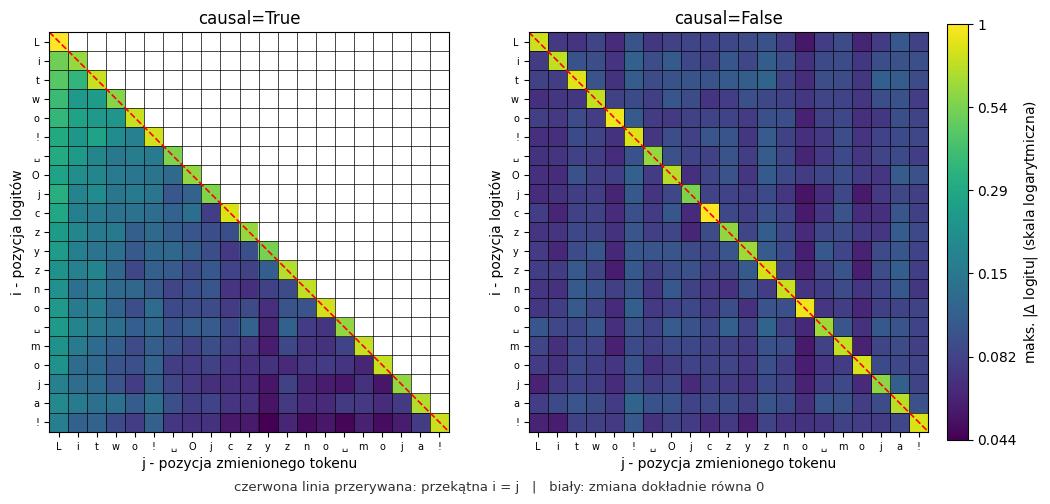

In [11]:
import numpy as np                       # do maskowania dokładnych zer
from matplotlib.colors import LogNorm    # skala logarytmiczna

PROMPT = "Litwo! Ojczyzno moja!"
idx = torch.tensor([encode(PROMPT)], device=device)

D = {}
for causal in (True, False):
    torch.manual_seed(SEED)
    m = GPTModel(GPTConfig(causal=causal)).to(device)
    D[causal] = dependency_matrix(m, idx).numpy()

# Wspólna dla obu wykresów skala logarytmiczna: wartości rozciągają się na ponad rząd
# wielkości (mediana ~0,1, przekątna ~0,8), więc na skali liniowej widać tylko przekątną.
# Dokładne zera są maskowane i rysowane na biało - od razu widać, gdzie zależności nie ma.
nz = np.concatenate([A[A > 0] for A in D.values()])
norm = LogNorm(vmin=nz.min(), vmax=nz.max())
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("white")

labels = [c if c != " " else "␣" for c in PROMPT]
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))
for ax, causal in zip(axes, (True, False)):
    A = np.ma.masked_where(D[causal] == 0, D[causal])
    im = ax.imshow(A, cmap=cmap, norm=norm)
    ax.set_title(f"causal={causal}")
    ax.set_xlabel("j - pozycja zmienionego tokenu")
    ax.set_ylabel("i - pozycja logitów")
    ax.set_xticks(range(len(PROMPT)), labels, fontsize=7)
    ax.set_yticks(range(len(PROMPT)), labels, fontsize=7)
    ax.set_xticks(np.arange(-0.5, len(PROMPT), 1), minor=True)   # siatka na granicach komórek
    ax.set_yticks(np.arange(-0.5, len(PROMPT), 1), minor=True)
    ax.grid(which="minor", color="black", lw=0.5)
    ax.tick_params(which="minor", length=0)
    ax.plot([-0.5, len(PROMPT) - 0.5], [-0.5, len(PROMPT) - 0.5],
            color="red", lw=1.2, ls="--")          # przekątna i = j

ticks = np.geomspace(nz.min(), nz.max(), 6)                      # opisane wartości na pasku kolorów
cb = fig.colorbar(im, ax=axes, fraction=0.035, pad=0.02, ticks=ticks)
cb.ax.set_yticklabels([f"{t:.2g}" for t in ticks])
cb.minorticks_off()
cb.set_label("maks. |$\Delta$ logitu| (skala logarytmiczna)")
fig.text(0.5, 0.015, "czerwona linia przerywana: przekątna i = j   |   biały: zmiana dokładnie równa 0",
         ha="center", fontsize=9.5, color="#333333")
plt.show()

**Pytanie 2.** (a) Dlaczego przekątna macierzy dla modelu z maską jest niezerowa - czy to nie jest "podglądanie" odpowiedzi? (b) Co by się stało, gdybyśmy trenowali model bez maski przyczynowej na zadaniu przewidywania następnego tokenu? Jaką stratę osiągnie taki model? Sprawdzisz to w części 1B.

**Odpowiedź:** (a) Na przekatnej pokazane sa pozycje reakcji na zmiane znaku. Logity na pozycji i, przewiduja znak na pozycji i+1, wiec nie jest to podgladanie tylko model korzysta z biezacego znaku.

(b) Bez maski dana pozycja i nie przewiduje a podglada pozycje i+1. Wteyd model uczy się na pamięc przepisywania znaku ktory stoi obok, a nie przewidywania i uczenia sie jezyka. Strata spadnie do 0, natomiast generowany tekst nie bedzie poprawny, bo model nauczyl sie na pamiec. Niska strata nie gwarantuje dobrego modelu, jesli w danych jest przeciek.

#### Zadanie 3. Test permutacji - skąd model wie, na której pozycji jest token?

Funkcja $f$ przekształcająca sekwencje jest **ekwiwariantna względem permutacji**, jeśli permutacja wejścia powoduje taką samą permutację wyjścia: $f(x_\pi) = f(x)_\pi$.

Napisz funkcję `permutation_error(model, idx, perm)`, która zwraca maksymalną różnicę bezwzględną między `model(idx[:, perm])` a `model(idx)[:, perm]` (tryb `eval()`, bez gradientów). Następnie uruchom komórkę z testem dla czterech kombinacji flag `pos_emb` i `causal`.

In [12]:
@torch.no_grad()
def permutation_error(model: GPTModel, idx: Tensor, perm: Tensor) -> float:
    model.eval()
    # TODO:
    # 1. wyjście dla permutowanego wejścia: model(idx[:, perm])        - wymiar (1, T, V)
    out_a = model(idx[:, perm])
    # 2. permutowane wyjście dla oryginalnego wejścia: model(idx)[:, perm]
    out_b = model(idx)[:, perm]
    # 3. zwróć maksymalną różnicę bezwzględną jako liczbę (.max().item())
    return (out_a - out_b).abs().max().item()
    #raise NotImplementedError

**Przewidywanie.** Dla których z czterech kombinacji (`pos_emb` ∈ {True, False}) × (`causal` ∈ {True, False}) model będzie ekwiwariantny względem permutacji (błąd rzędu $10^{-6}$)? Uzasadnij.

**Moje przewidywanie (wpisz PRZED uruchomieniem kolejnej komórki):**

Ekwiwariantny będzie tylko model bez embeddingów pozycyjnych i bez maski (`pos_emb=False, causal=False`).
Atencja porównuje treść tokenów (q·k) i liczy ważoną sumę, która nie zależy od kolejności, a embedding tokenu, FF i LayerNorm działają na każdą pozycję osobno, więc taki model nie ma żadnej informacji o pozycji i przestawienie wejścia tylko tak samo przestawi wyjście (błąd ~$10^{-6}$, szum numeryczny).
W pozostałych przypadkach jest źródło informacji o pozycji: embeddingi pozycyjne (do tokenu dodawany jest wektor zależny od miejsca) albo maska (pozycja $i$ widzi $i+1$ tokenów, więc ilość widzianych tokenów zdradza pozycję), więc błąd będzie duży.

| `pos_emb` | `causal` | źródło informacji o pozycji | ekwiwariantny? |
|---|---|---|---|
| False | False | brak | **TAK** (błąd ~$10^{-6}$) |
| False | True | maska przyczynowa | NIE |
| True | False | embeddingi pozycyjne | NIE |
| True | True | maska + embeddingi | NIE |

In [13]:
torch.manual_seed(SEED)
idx = torch.randint(vocab_size, (1, 32), device=device)
perm = torch.randperm(32, device=device)

# Legenda (wynika wprost z flag, nie z pomiaru) - co w danej konfiguracji może nieść informację o pozycji
ZRODLO = {(False, False): "brak",
          (False, True):  "maska przyczynowa",
          (True,  False): "embeddingi pozycji",
          (True,  True):  "maska + embeddingi"}

print(f"{'pos_emb':>8} {'causal':>7} {'maks |f(x_π) - f(x)_π|':>24}   "
      f"{'źródło informacji o pozycji':<30}{'czy odróżnia kolejność?'}")
for pos_emb in (False, True):
    for causal in (False, True):
        torch.manual_seed(SEED)
        m = GPTModel(GPTConfig(pos_emb=pos_emb, causal=causal)).to(device)
        err = permutation_error(m, idx, perm)
        # Werdykt wynika z pomiaru: różnica rzędu 1e-7 to szum zmiennoprzecinkowy, nie realna zależność
        werdykt = "NIE - model ekwiwariantny" if err < 1e-4 else "TAK"
        print(f"{pos_emb!s:>8} {causal!s:>7} {err:24.2e}   {ZRODLO[pos_emb, causal]:<30}{werdykt}")

 pos_emb  causal   maks |f(x_π) - f(x)_π|   źródło informacji o pozycji   czy odróżnia kolejność?
   False   False                 4.47e-07   brak                          NIE - model ekwiwariantny
   False    True                 1.37e+00   maska przyczynowa             TAK
    True   False                 9.87e-01   embeddingi pozycji            TAK
    True    True                 1.13e+00   maska + embeddingi            TAK


**Pytanie 3.** (a) Co ten wynik mówi o roli embeddingów pozycyjnych w modelu bez maski (np. w koderze typu BERT)? (b) Model z maską przyczynową, ale **bez** embeddingów pozycyjnych nie jest ekwiwariantny. Jak taki model może "wiedzieć", na której pozycji się znajduje? Wróć do tego pytania po ablacji `pos_emb=False` w części 1B.

**Odpowiedź:**

(a) W moedlu bez maski kazda pozycja widzi wszystkie znaki, wiec wtedy embeddingi pozycyjne sa jedynym zrodlem informacji o kolejnosci znakow. Bez tych embeddingow, model traktuje tekst jak worek slow.

(b) Stosowana maska przyczynowa sprawia, ze kazda pozycja widzi inna liczbe tokenow. Pozycja 0 widzi 1 token, ..... pozycja 31 widzi 32 tokeny.
Na pozycji 0. funkcja softmax ma tylko jeden element i latwo przewidziec/rozpoznac dana pozycje. Na dalszych pozycjach uwaga jest rozkladana na coraz wieksza liczbe tokenow i przewidywanie staje sie trudniejsze.

## Część 1B. Trenowanie nanoGPT (model znakowy)

W tej części trenujemy model `GPTModel` na tekście *Pana Tadeusza*, a następnie sprawdzamy, jak usunięcie poszczególnych elementów architektury wpływa na trening.

Pętla treningowa jest gotowa (ukryta komórka poniżej - nie musisz jej czytać). Funkcja `train_gpt(cfg, ...)`:
- tworzy model `GPTModel(cfg)` z ziarnem `SEED`,
- trenuje go optymalizatorem AdamW przez `max_steps` kroków na losowych wsadach z `get_batch`,
- stosuje rozgrzewkę (*warmup*) i kosinusowe zmniejszanie współczynnika uczenia, obcinanie normy gradientu i obliczenia w mieszanej precyzji (na GPU),
- co `eval_every` kroków wyznacza średnią stratę na zbiorze treningowym i walidacyjnym (w trybie `eval()`) i wypisuje próbkę wygenerowanego tekstu,
- zwraca parę `(model, history)`, gdzie `history` to słownik z listami `step`, `train_loss`, `val_loss` oraz czasem treningu `time_s`.

Funkcja `generate(model, prompt, ...)` generuje kontynuację tekstu, losując kolejne znaki z rozkładu zwracanego przez model (strategie generowania będą tematem osobnego notatnika).

In [ ]:
# @title Funkcje pomocnicze: trening i generowanie tekstu (nie trzeba czytać)
import warnings

# GradScaler może pominąć pierwsze kroki (przepełnienie fp16) - to normalne, ukrywamy ostrzeżenie
warnings.filterwarnings("ignore", message=r"Detected call of `lr_scheduler.step\(\)`")


@torch.no_grad()
def generate(model: GPTModel, prompt: str, max_new_chars: int = 300,
             temperature: float = 0.8, seed: int | None = None) -> str:
    """Generuje kontynuację promptu, losując kolejne znaki z rozkładu zwracanego przez model."""
    model.eval()
    gen = torch.Generator(device=device).manual_seed(SEED if seed is None else seed)
    idx = torch.tensor([encode(prompt)], device=device)
    for _ in range(max_new_chars):
        logits = model(idx[:, -model.cfg.context_length:])[:, -1, :].float() / temperature
        next_id = torch.multinomial(torch.softmax(logits, dim=-1), num_samples=1, generator=gen)
        idx = torch.cat([idx, next_id], dim=1)
    return decode(idx[0].tolist())


@torch.no_grad()
def estimate_loss(model: GPTModel, batch_size: int, eval_iters: int, use_amp: bool) -> dict[str, float]:
    model.eval()
    out = {}
    for split in ("train", "val"):
        losses = []
        for _ in range(eval_iters):
            x, y = get_batch(split, batch_size, model.cfg.context_length)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                logits = model(x)
            losses.append(F.cross_entropy(logits.float().flatten(0, 1), y.flatten()).item())
        out[split] = sum(losses) / len(losses)
    model.train()
    return out


def train_gpt(cfg: GPTConfig, *, max_steps: int = 3000, batch_size: int = 64, lr: float = 1e-3,
              warmup_steps: int = 100, weight_decay: float = 0.1, eval_every: int = 250,
              eval_iters: int = 50, fixed_batch: bool = False, sample_prompt: str = "Litwo! ",
              verbose: bool = True) -> tuple[GPTModel, dict]:
    """Trenuje GPTModel(cfg). fixed_batch=True: trening na jednym, stałym wsadzie (test przeuczenia)."""
    torch.manual_seed(SEED)
    model = GPTModel(cfg).to(device)
    use_amp = device.type == "cuda"

    # Weight decay tylko dla macierzy wag (nie dla obciążeń i parametrów LayerNorm)
    decay = [p for p in model.parameters() if p.dim() >= 2]
    no_decay = [p for p in model.parameters() if p.dim() < 2]
    optimizer = torch.optim.AdamW([{"params": decay, "weight_decay": weight_decay},
                                   {"params": no_decay, "weight_decay": 0.0}], lr=lr, betas=(0.9, 0.99))

    def lr_lambda(step: int) -> float:
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = (step - warmup_steps) / max(1, max_steps - warmup_steps)
        return 0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * progress))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    history = {"step": [], "train_loss": [], "val_loss": []}
    fixed = get_batch("train", batch_size, cfg.context_length) if fixed_batch else None

    if verbose:
        print(f"Parametry: {count_params(model):,}")
        if fixed_batch:
            # treść wsadu, żeby było z czym porównać próbki generowane niżej
            print(f"wsad (prawda): {decode(fixed[0][0, :78].tolist())!r}\n")
    t0 = time.time()
    model.train()
    for step in range(1, max_steps + 1):
        x, y = fixed if fixed_batch else get_batch("train", batch_size, cfg.context_length)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logits = model(x)
        loss = F.cross_entropy(logits.float().flatten(0, 1), y.flatten())
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        if step % eval_every == 0 or step == max_steps:
            if fixed_batch:
                tr, va = loss.item(), float("nan")
            else:
                losses = estimate_loss(model, batch_size, eval_iters, use_amp)
                tr, va = losses["train"], losses["val"]
            history["step"].append(step)
            history["train_loss"].append(tr)
            history["val_loss"].append(va)
            if verbose:
                print(f"krok {step:5d} | strata: train {tr:.3f}, val {va:.3f} | perplexity val {math.exp(va):6.2f} | "
                      f"BPC val {va / math.log(2):.3f} | {time.time() - t0:5.0f} s")
                if fixed_batch:
                    # próbka promptowana początkiem stałego wsadu - widać, jak model uczy się go na pamięć
                    prompt = decode(fixed[0][0, :30].tolist())
                    sample = generate(model, prompt, max_new_chars=48).replace("\n", " / ")
                    print(f"              model: {sample!r}")
                else:
                    sample = generate(model, sample_prompt, max_new_chars=80).replace("\n", " / ")
                    print(f"           {sample}")
                model.train()
    history["time_s"] = time.time() - t0
    return model, history


def plot_history(history: dict, title: str = ""):
    plt.figure(figsize=(7, 4))
    plt.plot(history["step"], history["train_loss"], "o-", label="train")
    if not all(math.isnan(v) for v in history["val_loss"]):
        plt.plot(history["step"], history["val_loss"], "o-", label="val")
    plt.xlabel("krok")
    plt.ylabel("strata (entropia krzyżowa, nat/znak)")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

Konfiguracja bazowa nanoGPT: 4 bloki, 4 głowice, $C = 256$, kontekst 128 znaków, dropout 0,2 (ok. 3,2 mln parametrów).

In [ ]:
BASE = GPTConfig(dropout=0.2)
TRAIN_STEPS = 3000
print(BASE)

### Zadanie 4. Test przeuczenia jednego wsadu

Zanim uruchomimy długi trening, sprawdzamy, czy model potrafi "nauczyć się na pamięć" jednego wsadu danych (wyłączamy dropout).

**Przewidywanie.** Jak powinna zachowywać się strata przy treningu na jednym, stałym wsadzie? Jakie błędy w implementacji mógłby wykryć ten test?

**Moje przewidywanie (wpisz PRZED uruchomieniem kolejnej komórki):** _(uzupełnij)_

In [ ]:
_, hist_overfit = train_gpt(replace(BASE, dropout=0.0), fixed_batch=True, max_steps=300, eval_every=25)
plot_history(hist_overfit, "Trening na jednym wsadzie")

**Pytanie 4.** Jaką stratę osiągnął model po 300 krokach? Dlaczego ten test nic nie mówi o tym, czy model dobrze modeluje język?

**Odpowiedź:** _(uzupełnij)_

### Zadanie 5. Model bazowy

Wytrenuj model bazowy (na GPU kilka minut).

In [ ]:
model_base, hist_base = train_gpt(BASE, max_steps=TRAIN_STEPS)
plot_history(hist_base, "Model bazowy")
print(f"Czas treningu: {hist_base['time_s']:.0f} s")

#### Miary jakości modelu językowego

Strata to średnia entropia krzyżowa na **token**, w natach: $L = -\frac{1}{N}\sum_t \ln p(x_t \mid x_{<t})$. Na jej podstawie podaje się dwie popularne miary:

| Miara | Wzór | Interpretacja |
|---|---|---|
| **perplexity** (na token) | $e^{L}$ | model jest średnio tak niepewny, jakby wybierał spośród $e^{L}$ równie prawdopodobnych tokenów; najczęściej podawana miara modeli językowych |
| **BPC** (*bits per character*) | $\dfrac{L}{\ln 2} \cdot \dfrac{\text{liczba tokenów}}{\text{liczba znaków}}$ | średnia liczba bitów potrzebna do zakodowania jednego **znaku** tekstu; nie zależy od tokenizatora |

W modelu znakowym jeden token to jeden znak, więc $\mathrm{BPC} = L / \ln 2$. Obie miary wrócą w części 2, gdzie porównamy model znakowy z modelem używającym tokenizatora BPE.

Uzupełnij komórkę: wyznacz końcową stratę walidacyjną, perplexity i BPC. Następnie wygeneruj po 300 znaków dla promptu `"Litwo! Ojczyzno moja! "` oraz dla dwóch własnych promptów.

In [ ]:
# TODO:
# 1. końcowa strata walidacyjna to ostatni element listy hist_base["val_loss"]
# 2. wypisz ją oraz BPC (strata / math.log(2)) i perplexity (math.exp(strata))
# 3. dla promptu "Litwo! Ojczyzno moja! " i dwóch własnych wywołaj generate(model_base, prompt, max_new_chars=300)

Zapisujemy model bazowy - wrócimy do niego w części 2.

In [ ]:
torch.save(model_base.state_dict(), "nanogpt_znakowy.pt")

**Pytanie 5.** (a) Czy model się przeucza? Odpowiedz na podstawie krzywych strat. (b) Czego model się nauczył, a czego nie? Przyjrzyj się wygenerowanym tekstom na różnych poziomach: znaki i słowa, interpunkcja, budowa wersów, gramatyka, sens. (c) Jak interpretujesz perplexity równą np. 5 dla modelu znakowego? (d) Pokaż, że dla modelu znakowego perplexity $= 2^{\mathrm{BPC}}$. Czy ta zależność zachodzi dla każdego modelu językowego?

**Odpowiedź:** _(uzupełnij)_

### Zadanie 6. Ablacje z treningiem

Każda ablacja to trening modelu z jedną zmianą względem `BASE`. Funkcja `run` trenuje model, zapisuje wynik w słowniku `RESULTS` i wypisuje próbkę tekstu; `compare` rysuje krzywe walidacyjne wybranych przebiegów i tabelę wyników.

**Obowiązkowe:** (a) bez maski przyczynowej, (b) bez embeddingów pozycyjnych, (c) bez połączeń rezydualnych, (d) bez LayerNorm.
**Do wyboru** (co najmniej dwie): (e) liczba głowic, (f) głębokość vs szerokość, (g) długość kontekstu, (h) dropout, albo własny pomysł (np. `tie_weights`, inny współczynnik uczenia).

Do każdej ablacji wpisz przewidywanie **przed** uruchomieniem, a po treningu krótko opisz obserwacje: strata train/val w porównaniu z modelem bazowym, jakość tekstu, wyjaśnienie.

In [ ]:
RESULTS = {"base": {"cfg": BASE, **hist_base}}


def run(name: str, cfg: GPTConfig, **train_kwargs) -> GPTModel:
    model, hist = train_gpt(cfg, max_steps=train_kwargs.pop("max_steps", TRAIN_STEPS), verbose=False, **train_kwargs)
    RESULTS[name] = {"cfg": cfg, "params": count_params(model), **hist}
    print(f"{name}: strata train {hist['train_loss'][-1]:.3f}, val {hist['val_loss'][-1]:.3f}, "
          f"czas {hist['time_s']:.0f} s, parametry {count_params(model):,}")
    print(generate(model, "Litwo! Ojczyzno moja! ", max_new_chars=200))
    return model


def compare(names: list[str], title: str = ""):
    plt.figure(figsize=(7, 4))
    for name in names:
        r = RESULTS[name]
        plt.plot(r["step"], r["val_loss"], "o-", label=name)
    plt.xlabel("krok")
    plt.ylabel("strata walidacyjna")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
    print(f"{'przebieg':<22}{'train':>8}{'val':>8}{'min val':>9}{'ppl val':>9}{'BPC val':>9}")
    for name in names:
        r = RESULTS[name]
        va = r["val_loss"][-1]
        print(f"{name:<22}{r['train_loss'][-1]:8.3f}{va:8.3f}{min(r['val_loss']):9.3f}{math.exp(va):9.2f}"
              f"{va / math.log(2):9.3f}")

#### Ablacje obowiązkowe

**(a) Bez maski przyczynowej**

**Moje przewidywanie (wpisz PRZED uruchomieniem kolejnej komórki):** _(uzupełnij)_

In [ ]:
m_no_causal = run("no_causal", replace(BASE, causal=False))
compare(["base", "no_causal"])

**Pytanie (a).** Jak wyglądają straty i wygenerowany tekst? Wyjaśnij tę rozbieżność, nawiązując do zadania 2.

**Odpowiedź:** _(uzupełnij)_

**(b) Bez embeddingów pozycyjnych**

**Moje przewidywanie (wpisz PRZED uruchomieniem kolejnej komórki):** _(uzupełnij)_

In [ ]:
m_no_pos_emb = run("no_pos_emb", replace(BASE, pos_emb=False))
compare(["base", "no_pos_emb"])

**Pytanie (b).** O ile pogorszyła się strata? Czy model całkowicie stracił informację o kolejności znaków (nawiąż do pytania 3b)? Co w generowanym tekście ucierpiało najbardziej?

**Odpowiedź:** _(uzupełnij)_

**(c) Bez połączeń rezydualnych**

**Moje przewidywanie (wpisz PRZED uruchomieniem kolejnej komórki):** _(uzupełnij)_

In [ ]:
m_no_residual = run("no_residual", replace(BASE, residual=False))
compare(["base", "no_residual"])

**Pytanie (c).** Policz entropię rozkładu częstości znaków w tekście treningowym, $H = -\sum_c p(c) \ln p(c)$ (komórka poniżej), i porównaj ją ze stratą modelu. Czego nauczył się model? Dlaczego bez połączeń rezydualnych trening zawodzi, skoro w części 1A test permutacji i przyczynowości przechodziły?

In [ ]:
# TODO: entropia rozkładu częstości znaków

**Odpowiedź:** _(uzupełnij)_

**(d) Bez LayerNorm**

**Moje przewidywanie (wpisz PRZED uruchomieniem kolejnej komórki):** _(uzupełnij)_

In [ ]:
m_no_layernorm = run("no_layernorm", replace(BASE, layernorm=False))
compare(["base", "no_layernorm"])

**Pytanie (d).** Porównaj wynik z modelem bazowym i z ablacją (c). Który z dwóch elementów (rezydua czy normalizacja) jest ważniejszy dla tego modelu? Czy wniosek musi być taki sam dla modelu z 48 warstwami?

**Odpowiedź:** _(uzupełnij)_

#### Ablacje do wyboru (co najmniej dwie)

Poniżej propozycje. Dla każdej wybranej ablacji dodaj komórkę z przewidywaniem, komórkę z kodem i komórkę z obserwacjami.

- **(e) Liczba głowic:** `n_heads=1` i `n_heads=16` przy tym samym `emb_dim` (liczba parametrów się nie zmienia - dlaczego?).
- **(f) Głębokość vs szerokość** przy podobnej liczbie parametrów: np. `n_layers=2, emb_dim=384, n_heads=6` oraz `n_layers=8, emb_dim=192, n_heads=4`.
- **(g) Długość kontekstu:** `context_length=16` (ok. 2-3 słowa) zamiast 128.
- **(h) Dropout:** `dropout=0.0` - porównaj krzywe train i val z modelem bazowym.

### Zadanie 7. Wnioski z ablacji

Podsumuj wyniki ablacji w tabeli (przebieg, strata train, strata val, krótka obserwacja) i w kilku zdaniach odpowiedz: które elementy architektury okazały się **niezbędne** dla tego modelu, a które poprawiają wynik tylko nieznacznie? Czy Twoim zdaniem wnioski przeniosą się na duże modele (dziesiątki warstw, miliardy parametrów)? Uzasadnij.

**Odpowiedź:** _(uzupełnij)_

### Zadanie D (opcjonalne). Mapy atencji

Funkcja `attention_maps` zwraca wagi atencji wszystkich bloków (model pre-LN z rezyduami) dla podanego tekstu. Narysuj mapy atencji modelu bazowego dla fragmentu wersu (wszystkie głowice w pierwszym i ostatnim bloku). Znajdź co najmniej dwie głowice o czytelnym wzorcu (np. atencja na poprzedni znak, na początek słowa, na ostatnią spację lub znak nowej linii) i opisz je.

In [ ]:
import numpy as np                      # do siatki i maskowania zer
from matplotlib.colors import LogNorm    # skala logarytmiczna


@torch.no_grad()
def attention_maps(model: GPTModel, s: str) -> list[Tensor]:
    """Lista (po blokach) tensorów (h, T, T) z wagami atencji dla tekstu s."""
    model.eval()
    idx = torch.tensor([encode(s)], device=device)
    x = model.tok_emb(idx)
    if model.pos_emb is not None:                  # model z ablacji (b) nie ma embeddingów pozycji
        x = x + model.pos_emb(torch.arange(idx.shape[1], device=device))
    maps = []
    for block in model.blocks:
        h, att = block.attn(block.norm1(x), return_attn=True)
        maps.append(att[0].float().cpu())
        x = x + h if block.residual else h         # ablacja (c): bez połączeń rezydualnych
        h = block.ff(block.norm2(x))
        x = x + h if block.residual else h
    return maps


def plot_attention(maps: list[Tensor], s: str, layer: int):
    att = maps[layer]
    n_heads = att.shape[0]
    fig, axes = plt.subplots(1, n_heads, figsize=(4.9 * n_heads, 4.6))
    labels = [c if c != " " else "␣" for c in s]
    # skala logarytmiczna - wagi atencji rozciągają się na wiele rzędów wielkości
    # (mediana ~1e-3, przekątna ~1), więc na skali liniowej widać tylko przekątną.
    norm = LogNorm(vmin=1e-4, vmax=1.0)
    cmap = plt.get_cmap("Blues").copy()
    cmap.set_bad("#ededed")                      # pozycje zamaskowane (waga dokładnie 0)
    for hd, ax in enumerate(axes):
        A = np.ma.masked_where(att[hd].numpy() == 0, att[hd].numpy())
        im = ax.imshow(A, cmap=cmap, norm=norm)
        ax.set_xticks(range(len(s)), labels, fontsize=7)
        ax.set_yticks(range(len(s)), labels, fontsize=7)
        ax.set_xticks(np.arange(-0.5, len(s), 1), minor=True)    # siatka na granicach komórek
        ax.set_yticks(np.arange(-0.5, len(s), 1), minor=True)
        ax.grid(which="minor", color="black", lw=0.3)
        ax.tick_params(which="minor", length=0)
        ax.set_title(f"blok {layer}, głowica {hd}")
        cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02, extend="min",
                          ticks=[1e-4, 1e-3, 1e-2, 1e-1, 1])      # opisany pasek kolorów
        cb.ax.set_yticklabels(["0,0001", "0,001", "0,01", "0,1", "1"])
        cb.set_label("waga atencji (skala log.)", fontsize=8)
        cb.ax.tick_params(labelsize=7)
    fig.text(0.5, -0.02, "szare pola: pozycje zamaskowane, waga dokładnie 0   |   "
             "wagi poniżej 0,0001 rysowane są kolorem najjaśniejszym",
             ha="center", fontsize=9, color="#444444")
    plt.tight_layout()
    plt.show()

In [ ]:
# TODO

**Odpowiedź:** _(uzupełnij)_

## Część 2. Wstępnie wytrenowany model GPT

W części 1 wytrenowaliśmy od zera mały model znakowy (3 mln parametrów) na jednym utworze. Prawdziwe modele językowe powstają inaczej: najpierw **wstępny trening** (*pretraining*) dużego modelu na ogromnym, zróżnicowanym korpusie, potem **dostrajanie** (*fine-tuning*) do konkretnego zadania lub stylu na małym zbiorze (dostrajaniu poświęcony jest osobny notatnik).

Przygotowaliśmy model `jac99/pl-speakleash-gpt-98m`:

| | |
|---|---|
| Architektura | **dokładnie klasa `GPTModel`** z części 1A: 12 bloków, $C = 768$, 12 głowic, kontekst 1024 tokenów, współdzielone wagi embeddingów i głowicy |
| Parametry | ok. 98 mln (ok. 30 razy więcej niż model znakowy) |
| Tokenizator | BPE, 16 000 tokenów (`jac99/pl-speakleash-bpe-16k`) |
| Dane | ok. 9,4 mld tokenów (37,6 mld znaków) polskich tekstów z korpusu [SpeakLeash](https://speakleash.org/): artykuły, blogi, fora, Wikipedia, literatura, napisy filmowe... |
| Trening | 25 mld tokenów (ok. 2,7 epoki), ok. 3 doby na dwóch kartach RTX 2080 Ti |

W tej części wczytasz wagi do klasy `GPTModel` z części 1A, porównasz modele różnymi miarami, zajrzysz w przebieg treningu i sprawdzisz, jak zmienia się rozkład prawdopodobieństwa następnego tokenu w trakcie treningu.

**Wymagania:** wykonane komórki z części 0 i 1A (definicje klas `GPTConfig` ... `GPTModel`). Do porównania w zadaniu 9 potrzebny jest też plik `nanogpt_znakowy.pt` zapisany w zadaniu 5. Model zajmuje ok. 0,4 GB i mieści się w pamięci karty T4. Jeśli zabraknie pamięci GPU, uruchom środowisko ponownie i wykonaj tylko część 0, 1A i 2.

In [ ]:
import gc
import json
import os

from huggingface_hub import hf_hub_download, snapshot_download
from safetensors.torch import load_model
from transformers import AutoTokenizer

MODEL_REPO = "jac99/pl-speakleash-gpt-98m"

# Zwolnienie pamięci GPU po części 1B
for name in [n for n, v in list(globals().items()) if isinstance(v, nn.Module)]:
    del globals()[name]
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Pobieramy konfigurację, model końcowy, tokenizator, logi treningu i dane referencyjne (bez migawek)
model_dir = MODEL_REPO if os.path.isdir(MODEL_REPO) else snapshot_download(
    MODEL_REPO, allow_patterns=["*.json", "*.jsonl", "*.md", "model.safetensors", "reference.pt"])


def model_file(rel_path: str) -> str:
    # Plik z repozytorium modelu (pobierany na żądanie, np. migawki z treningu)
    local = os.path.join(model_dir, rel_path)
    return local if os.path.exists(local) else hf_hub_download(MODEL_REPO, rel_path)


tokenizer = AutoTokenizer.from_pretrained(model_dir)
model_info = json.load(open(os.path.join(model_dir, "config.json")))
assert model_info["model"].pop("pre_ln", True)   # model wytrenowano w wariancie pre-LN, jedynym w GPTModel
EOT = tokenizer.eos_token_id
print(json.dumps(model_info["model"], indent=1))
print(f"Parametry: {model_info['params']:,}, tokeny treningowe: {model_info['tokens_seen'] / 1e9:.1f} mld")

### 2.1 Wczytanie wag modelu

**Zadanie 8.** Napisz funkcję `load_pretrained(model_dir)`, która:
1. tworzy `GPTConfig` na podstawie słownika `model_info["model"]` (pola mają te same nazwy co w klasie `GPTConfig`),
2. tworzy `GPTModel` i wczytuje wagi z pliku `model.safetensors` funkcją `safetensors.torch.load_model(model, ścieżka)` (ta funkcja poprawnie obsługuje współdzielone wagi głowicy i embeddingów),
3. przenosi model na `device` i przełącza w tryb `eval()`.

Test porównuje logity wczytanego modelu z logitami zapisanymi przez autorów modelu dla tekstu referencyjnego - przy poprawnym wczytaniu wag różnice będą rzędu $10^{-4}$. Sprawdzamy obie implementacje atencji: ręczną (metoda `forward`) i szybką (`F.scaled_dot_product_attention`).

In [ ]:
def load_pretrained(model_dir: str) -> GPTModel:
    # TODO: kroki 1-3 opisane powyżej (GPTConfig(**słownik) tworzy konfigurację z pól słownika;
    #       ścieżka do wag: os.path.join(model_dir, "model.safetensors"))
    raise NotImplementedError

In [ ]:
model = load_pretrained(model_dir)
ref = torch.load(os.path.join(model_dir, "reference.pt"))
with torch.no_grad():
    logits = model(ref["input_ids"].to(device)).float().cpu()       # ręczna atencja (forward)
    model.set_sdpa(True)
    logits_sdpa = model(ref["input_ids"].to(device)).float().cpu()  # szybka atencja
print(f"Parametry: {count_params(model):,}")
print(f"Maks. różnica logitów (ręczna atencja):  {(logits - ref['logits']).abs().max():.2e}")
print(f"Maks. różnica logitów (atencja SDPA):     {(logits_sdpa - ref['logits']).abs().max():.2e}")
assert torch.allclose(logits, ref["logits"], atol=1e-2), "Logity różnią się od referencyjnych - sprawdź funkcję load_pretrained (i implementację, jeśli używasz własnej)"
assert model.head.weight is model.tok_emb.weight, "Wagi głowicy i embeddingów powinny być współdzielone"
print("Test 8 zaliczony")

Tokenizator BPE dzieli tekst na fragmenty słów. Zobacz, jak wygląda tokenizacja kilku zdań i ile znaków przypada średnio na token. Zwróć uwagę, że **spacja jest doklejana na początku następnego słowa** (np. `' Warszawie'`) - wrócimy do tego w zadaniu 11.

In [ ]:
for s in ["W Warszawie odbył się mecz piłki nożnej.", "Litwo! Ojczyzno moja! ty jesteś jak zdrowie;",
          "Sztuczna inteligencja zmienia rynek pracy."]:
    print(tokenizer.tokenize(s))

pt_test = text[n_train:]           # ostatnie 10% "Pana Tadeusza" - ten sam fragment co val w części 1B
pt_test_ids = tokenizer.encode(pt_test)
print(f"\nPan Tadeusz (test): {len(pt_test):,} znaków, {len(pt_test_ids):,} tokenów BPE, "
      f"{len(pt_test) / len(pt_test_ids):.2f} znaku na token")

In [ ]:
# @title Funkcje pomocnicze: generowanie tekstu i log-prawdopodobieństwo tekstu (nie trzeba czytać)

@torch.no_grad()
def generate_bpe(model: GPTModel, prompt: str, max_new_tokens: int = 100, temperature: float = 0.7,
                 greedy: bool = False, seed: int | None = None) -> str:
    """Generuje kontynuację promptu; kończy na tokenie <|endoftext|>."""
    model.eval()
    gen = torch.Generator(device=device).manual_seed(SEED if seed is None else seed)
    idx = torch.tensor([tokenizer.encode(prompt)], device=device)
    for _ in range(max_new_tokens):
        logits = model(idx[:, -model.cfg.context_length:])[:, -1, :].float()
        if greedy:
            next_id = logits.argmax(dim=-1, keepdim=True)
        else:
            next_id = torch.multinomial(torch.softmax(logits / temperature, dim=-1), 1, generator=gen)
        if next_id.item() == EOT:
            break
        idx = torch.cat([idx, next_id], dim=1)
    return tokenizer.decode(idx[0].tolist())


@torch.no_grad()
def text_nll(model: GPTModel, ids: list[int], ctx: int | None = None, batch_size: int = 8) -> tuple[float, int]:
    """Suma ujemnych log-prawdopodobieństw [nat] tokenów tekstu i liczba ocenionych tokenów.

    Tekst jest dzielony na okna długości ctx przesuwane o ctx/2; każdy token (oprócz pierwszego) jest
    oceniany dokładnie raz, w większości przypadków z co najmniej ctx/2 tokenami kontekstu.
    """
    model.eval()
    if len(ids) < 3:
        return 0.0, 0
    ctx = min(ctx or model.cfg.context_length, len(ids) - 1)
    data = torch.tensor(ids, dtype=torch.long)
    last = len(ids) - 1 - ctx
    starts = sorted(set(list(range(0, last + 1, max(1, ctx // 2))) + [last]))
    total, n, next_target = 0.0, 0, 1
    for b in range(0, len(starts), batch_size):
        chunk = starts[b:b + batch_size]
        x = torch.stack([data[s:s + ctx] for s in chunk]).to(device)
        y = torch.stack([data[s + 1:s + ctx + 1] for s in chunk]).to(device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            logits = model(x)
        nll = F.cross_entropy(logits.float().transpose(1, 2), y, reduction="none").cpu()   # (B, ctx)
        for row, s in zip(nll, chunk):
            first = max(0, next_target - (s + 1))          # pomijamy tokeny ocenione w poprzednim oknie
            total += row[first:].sum().item()
            n += len(row) - first
            next_target = s + ctx + 1
    return total, n

### 2.2 Perplexity czy BPC?

Porównamy model znakowy z części 1B z wstępnie wytrenowanym modelem BPE na tym samym tekście: ostatnich 10% *Pana Tadeusza*. Funkcja `text_nll` zwraca sumę ujemnych log-prawdopodobieństw tokenów tekstu (w natach) i liczbę ocenionych tokenów.

**Zadanie 9.** Napisz funkcję `metrics_from_nll(nll, n_tokens, n_chars, n_words)`, która zwraca słownik z miarami:
- `loss` - średnia strata na token [nat],
- `ppl_token` - perplexity na token,
- `bpc` - bity na znak,
- `ppl_char` - perplexity na znak ($2^{\mathrm{BPC}}$),
- `ppl_word` - perplexity na słowo (tym razem normalizujemy przez liczbę słów).

In [ ]:
def metrics_from_nll(nll: float, n_tokens: int, n_chars: int, n_words: int) -> dict[str, float]:
    # TODO: zastąp wielokropki wyrażeniami i usuń linię poniżej.
    raise NotImplementedError
    return {"loss":      ...,   # średnia strata na token [nat]
            "ppl_token": ...,   # perplexity na token
            "bpc":       ...,   # bity na znak - normalizacja przez znaki, nie przez tokeny
            "ppl_char":  ...,   # perplexity na znak = 2 ** bpc
            "ppl_word":  ...}   # perplexity na słowo - normalizacja przez liczbę słów

In [ ]:
m = metrics_from_nll(nll=100 * math.log(4), n_tokens=100, n_chars=200, n_words=50)
assert abs(m["loss"] - math.log(4)) < 1e-9 and abs(m["ppl_token"] - 4) < 1e-9
assert abs(m["bpc"] - 1.0) < 1e-9 and abs(m["ppl_char"] - 2.0) < 1e-9 and abs(m["ppl_word"] - 16.0) < 1e-9
print("Test 9 zaliczony")

In [ ]:
def evaluate_models(text_eval: str) -> dict[str, dict]:
    n_chars, n_words = len(text_eval), len(text_eval.split())
    rows = {}
    if os.path.exists("nanogpt_znakowy.pt"):
        char_model = GPTModel(GPTConfig(dropout=0.2)).to(device)
        char_model.load_state_dict(torch.load("nanogpt_znakowy.pt", map_location=device))
        nll, n = text_nll(char_model, encode(text_eval))
        rows["nanoGPT znakowy (cz. 1B)"] = {"chars_per_token": 1.0, **metrics_from_nll(nll, n, n_chars, n_words)}
        del char_model
    else:
        print("Brak pliku nanogpt_znakowy.pt - wykonaj zadanie 5, aby porównać z modelem znakowym.")
    ids = tokenizer.encode(text_eval)
    nll, n = text_nll(model, ids)
    rows["GPT-98M (BPE), bez dostrojenia"] = {"chars_per_token": n_chars / len(ids),
                                               **metrics_from_nll(nll, n, n_chars, n_words)}
    return rows


def print_table(rows: dict[str, dict]):
    print(f"{'model':<34}{'zn./tok.':>9}{'strata':>8}{'ppl tok.':>10}{'BPC':>7}{'ppl zn.':>9}{'ppl słowo':>11}")
    for name, r in rows.items():
        print(f"{name:<34}{r['chars_per_token']:9.2f}{r['loss']:8.3f}{r['ppl_token']:10.2f}{r['bpc']:7.3f}"
              f"{r['ppl_char']:9.2f}{r['ppl_word']:11.4g}")


MEASURES = evaluate_models(pt_test)
print_table(MEASURES)

**Pytanie 9.**
1. Który model jest lepszy według perplexity na token, a który według BPC? Dlaczego te miary dają różne odpowiedzi? Wyjaśnij, co się zmienia, gdy jeden token obejmuje średnio kilka znaków.
2. Dlaczego perplexity na słowo jest porównywalna między modelami? Kiedy i ta miara zawodzi?
3. Artykuł podaje: „nasz model osiąga perplexity 12 na korpusie X, poprzedni najlepszy wynik to 18”. Jakich informacji potrzebujesz, aby uznać to porównanie za uczciwe?

**Odpowiedź:** _(uzupełnij)_

### 2.3 Dynamika uczenia

W trakcie wstępnego treningu zapisywano **migawki** modelu (po 0,1%, 0,3%, 1%, 3%, 10%, 30% i 50% treningu) oraz log strat. Plik `snapshots/index.json` zawiera listę migawek ze stratą walidacyjną każdej z nich, a `training_log.jsonl` - historię treningu (strata treningowa co 50 kroków, ewaluacje z próbkami tekstu).

In [ ]:
snapshots = json.load(open(model_file("snapshots/index.json")))
log = [json.loads(l) for l in open(model_file("training_log.jsonl"))]
train_log = [r for r in log if r["type"] == "train"]
eval_log = [r for r in log if r["type"] == "eval"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot([r["tokens"] / 1e9 for r in train_log], [r["loss"] for r in train_log], lw=0.5, label="trening")
axes[0].plot([r["tokens"] / 1e9 for r in eval_log], [r["val_loss"] for r in eval_log], "o", ms=2, label="walidacja")
axes[0].set_xlabel("przetworzone tokeny [mld]"); axes[0].set_ylabel("strata [nat/token]"); axes[0].set_ylim(2, 6)
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].semilogx([s["tokens"] for s in snapshots], [s["val_loss"] for s in snapshots], "o-")
axes[1].set_xlabel("przetworzone tokeny (skala log.)"); axes[1].set_ylabel("strata walidacyjna migawki"); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
for s in snapshots:
    print(f"{s['file']:<38} krok {s['step']:6d}  {s['tokens'] / 1e9:7.3f} mld tok.  val {s['val_loss']:.3f}")

**Zadanie 10.** Dla każdej migawki z listy `snapshots`: wczytaj jej wagi do modelu (`load_model(model, model_file(s["file"]))`), wygeneruj kontynuację promptu `"Dawno, dawno temu"` (`generate_bpe`, 60 tokenów, `seed=0`) i policz BPC na tekście `pt_test` (funkcje `text_nll` i `metrics_from_nll`). Wyniki zbierz w liście słowników i narysuj BPC w funkcji liczby przetworzonych tokenów (skala logarytmiczna). Na koniec wczytaj ponownie model końcowy (`load_pretrained`).

Migawki zajmują po ok. 0,4 GB - pobranie wszystkich potrwa chwilę.

In [ ]:
dynamics = []
# TODO

model = load_pretrained(model_dir).set_sdpa(True)

**Pytanie 10.** (a) Opisz, czego model uczy się na kolejnych etapach treningu (znaki, słowa, gramatyka, styl, treść) - odwołaj się do wygenerowanych tekstów. (b) Dlaczego stratę w funkcji liczby przetworzonych tokenów warto rysować w skali logarytmicznej? Co dzieje się z tempem spadku straty w trakcie treningu? (c) Strata treningowa i walidacyjna w logu niemal się pokrywają, choć model widział dane ok. 2,7 razy. Co z tego wynika?

**Odpowiedź:** _(uzupełnij)_

### 2.4 Rozkład prawdopodobieństwa następnego tokenu

Model językowy dla każdego kontekstu zwraca **rozkład prawdopodobieństwa następnego tokenu** po całym słowniku (16 000 tokenów). Generowanie tekstu to wielokrotne losowanie z tego rozkładu. Zobaczymy, jak ten rozkład zmienia się w trakcie wstępnego treningu - na początku, we wczesnej fazie, w środku i na końcu treningu - dla zdań, których dokończenie wymaga wiedzy o świecie.

**Uwaga o spacjach.** Tokenizator dokleja spację **na początek** następnego słowa: `"Stolicą Polski jest"` dzieli się na `['S', 'toli', 'cą', ' Polski', ' jest']`, a dalszy ciąg to token w rodzaju `' Warszawa'` (ze spacją). Dlatego prompt **nie powinien kończyć się spacją** - samotna spacja na końcu byłaby osobnym tokenem `' '`, który w tekstach treningowych prawie nigdy nie poprzedza słowa. Sprawdzimy to na końcu zadania.

**Zadanie 11.** Napisz dwie funkcje:
- `next_token_probs(model, prompt)` - zwraca wektor prawdopodobieństw następnego tokenu `(V,)` dla podanego promptu,
- `top_tokens(probs, k)` - zwraca listę `k` najbardziej prawdopodobnych tokenów jako pary (tekst tokenu, prawdopodobieństwo), od najbardziej prawdopodobnego.

In [ ]:
@torch.no_grad()
def next_token_probs(model: GPTModel, prompt: str) -> Tensor:
    model.eval()
    # TODO:
    # 1. zamień prompt na identyfikatory tokenów (tokenizer.encode) i utwórz z nich tensor (1, T) na urządzeniu device
    # 2. policz logity modelu: (1, T, V) i wybierz logity dla OSTATNIEJ pozycji: (V,); zamień je na float (.float())
    # 3. zamień logity na prawdopodobieństwa (torch.softmax) i zwróć je na CPU (.cpu())
    raise NotImplementedError


def top_tokens(probs: Tensor, k: int = 10) -> list[tuple[str, float]]:
    # TODO: k największych prawdopodobieństw i ich indeksy: probs.topk(k);
    #       tekst tokenu o identyfikatorze i to tokenizer.decode([i]); zwróć listę par (tekst, prawdopodobieństwo)
    raise NotImplementedError

In [ ]:
probs = next_token_probs(model, "Stolicą Polski jest")
assert probs.shape == (len(tokenizer),), f"Zły wymiar: {probs.shape}"
assert abs(probs.sum().item() - 1) < 1e-3, "Prawdopodobieństwa powinny sumować się do 1"
top = top_tokens(probs, 10)
assert len(top) == 10 and all(isinstance(t, str) for t, _ in top), "top_tokens powinno zwracać 10 par (tekst, p)"
assert all(top[i][1] >= top[i + 1][1] for i in range(9)), "Tokeny powinny być posortowane malejąco"
print("Test 11 zaliczony")

**Przewidywanie.** Jak będzie wyglądał rozkład następnego tokenu dla promptu `"Stolicą Polski jest"` na początku treningu (0,1%), w środku i na końcu? Jakie tokeny będą najbardziej prawdopodobne i jak duże będą ich prawdopodobieństwa? Czy model końcowy (98 mln parametrów) wskaże `' Warszawa'` jako najbardziej prawdopodobny token?

**Moje przewidywanie (wpisz PRZED uruchomieniem kolejnej komórki):** _(uzupełnij)_

Komórka poniżej wczytuje kolejne migawki modelu (0,1%, 3%, 50% i 100% treningu) i dla każdego promptu wypisuje 10 najbardziej prawdopodobnych tokenów obok siebie, a pod nimi **entropię** rozkładu w bitach, $H = -\sum_v p(v) \log_2 p(v)$ - miarę niepewności modelu (rozkład jednostajny na 16 000 tokenach ma entropię $\log_2 16\,000 \approx 14$ bitów, a rozkład pewny - 0 bitów). Tokeny są wypisane w apostrofach, żeby było widać spacje (`' Kraków'`) i znaki nowej linii (`'\n'`). Możesz dopisać własne prompty.

W tabeli poniżej poprawne odpowiedzi pojawiają się jako fragmenty słów (<code>' Pary'</code>, <code>' zgi'</code>), bo tokenizator dzieli rzadsze wyrazy i formy fleksyjne, a częste - nie (<code>' Warszawa'</code> ma własny token). Nie da się tego zgadnąć; trzeba zapytać tokenizator, i służy do tego komórka poniżej.</span>

In [ ]:
# Jak sprawdzić, na jakie tokeny tokenizator dzieli dane słowo (przyda się przy czytaniu wyników niżej)
def pokaz_tokeny(*slowa: str):
    for w in slowa:
        print(f"{w!r:<14} -> {tokenizer.tokenize(w)}   identyfikatory: {tokenizer.encode(w)}")


# Częste słowa mają własny token, rzadsze i formy fleksyjne są dzielone na kawałki
pokaz_tokeny(" Kraków", " Londyn", " miasto", " Wisła", " województwa")

Pod każdą tabelą rysowany jest wykres <b>wędrówki tokenów</b>, które na którymś etapie zajmowały pierwsze miejsce: <b>oś lewa</b> (linia ciągła) to miejsce w rankingu w skali logarytmicznej, 1. miejsce na górze, <b>oś prawa</b> (linia przerywana) - prawdopodobieństwo. Widać na nim to, czego z samej tabeli nie da się odczytać: skąd dany token przyszedł i jak szybko.

In [ ]:
PROMPTS = ["Stolicą Polski jest", "Wisła wpada do", "Stolicą Francji jest", "Mikołaj Kopernik urodził się w",
           "Jeszcze Polska nie"]
CHECKPOINT_FRACTIONS = [0.001, 0.03, 0.5, 1.0]        # początek, wczesna faza, środek i koniec treningu
checkpoints = [min(snapshots, key=lambda s: abs(s["fraction"] - f)) for f in CHECKPOINT_FRACTIONS]


def entropy_bits(probs: Tensor) -> float:
    return -(probs * torch.log2(probs.clamp_min(1e-12))).sum().item()


dist = {}           # dist[(prompt, nr punktu kontrolnego)] = wektor prawdopodobieństw
for c, s in enumerate(checkpoints):
    load_model(model, model_file(s["file"]))
    for prompt in PROMPTS:
        dist[prompt, c] = next_token_probs(model, prompt)


# Wykres wędrówki tokenów, które na którymś etapie były pierwsze.
# Oś lewa (linia ciągła) - miejsce w rankingu, oś prawa (przerywana) - prawdopodobieństwo.
PALETA = ["#2a78d6", "#eb6834", "#008300", "#00b8d9", "#4a3aa7", "#1baf7a", "#e34948", "#eda100"]
ZNACZNIKI = ["o", "s", "^", "D", "v", "P", "X", "*"]
# Chcesz wyróżnić na wykresie wybrany token (np. swój typ na poprawną odpowiedź)?
# Dopisz go tutaj w postaci: {"<prompt>": "<token>"}
ODPOWIEDZI = {}


def wykres_wedrowki(prompt: str, poprawna: str | None = None, czolo: int = 1):
    rozklady = [dist[prompt, c].numpy() for c in range(len(checkpoints))]
    kand = [tokenizer.encode(poprawna)[0]] if poprawna else []
    for r in rozklady:
        kand += list(np.argsort(-r)[:czolo])
    kand = list(dict.fromkeys(int(t) for t in kand))[:len(PALETA)]

    fig, ax = plt.subplots(figsize=(6.0, 2.8))
    ax2 = ax.twinx()
    x = np.arange(len(checkpoints))
    for i, t in enumerate(kand):
        miejsca = [int((r > r[t]).sum()) + 1 for r in rozklady]
        praw = [float(r[t]) for r in rozklady]
        gruba = bool(poprawna) and t == tokenizer.encode(poprawna)[0]
        nazwa = repr(tokenizer.decode([t])) + ("  (poprawna)" if gruba else "")
        ax.plot(x, miejsca, "-", marker=ZNACZNIKI[i], color=PALETA[i], lw=2.2 if gruba else 1.5,
                ms=5, mec="white", mew=1.0, zorder=3, label=nazwa)
        ax2.plot(x, praw, "--", color=PALETA[i], lw=1.0, alpha=0.45, zorder=2)
    ax.set_yscale("log"); ax.invert_yaxis()
    ax.set_yticks([1, 10, 100, 1000, 10000]); ax.set_yticklabels(["1", "10", "100", "1000", "10000"])
    ax.set_ylabel("miejsce (linia ciągła)", fontsize=7.5)
    ax2.set_yscale("log"); ax2.set_ylabel("prawdopodob. (przerywana)", fontsize=7.5)
    ax.set_xticks(x, labels); ax.set_xlim(-0.15, len(x) - 0.85)
    ax.grid(alpha=0.3); ax.set_axisbelow(True); ax.tick_params(labelsize=7.5)
    ax2.tick_params(labelsize=7.5)
    ax.set_title(f"{prompt!r}", fontsize=9, loc="left", pad=5)
    fig.legend(*ax.get_legend_handles_labels(), frameon=False, fontsize=7.5, loc="lower center",
               ncol=5, bbox_to_anchor=(0.5, -0.20), handlelength=1.6, columnspacing=1.2,
               handletextpad=0.5)
    plt.show()

labels = [f"{round(100 * s['fraction'], 1):g}% treningu" for s in checkpoints]
for prompt in PROMPTS:
    print(f"\n{prompt!r}")
    print("    " + "".join(f"{label:<24}" for label in labels))
    tops = [top_tokens(dist[prompt, c], 10) for c in range(len(checkpoints))]
    for r in range(10):
        print(f"{r + 1:>2}  " + "".join(f"{repr(t)[:15]:<16}{p:5.3f}   " for t, p in (top[r] for top in tops)))
    entropies = [f"{entropy_bits(dist[prompt, c]):.1f} bitu" for c in range(len(checkpoints))]
    print("H   " + "".join(f"{e:<24}" for e in entropies))
    wykres_wedrowki(prompt, ODPOWIEDZI.get(prompt))

Na koniec model końcowy: zachłanne dokończenie promptów (żeby zobaczyć całe słowa, nie tylko pierwszy token) oraz porównanie promptu bez spacji i ze spacją na końcu.

In [ ]:
model = load_pretrained(model_dir).set_sdpa(True)
for prompt in PROMPTS:
    print(f"{generate_bpe(model, prompt, max_new_tokens=8, greedy=True)!r}")

for prompt in ["Stolicą Polski jest", "Stolicą Polski jest "]:
    probs = next_token_probs(model, prompt)
    print(f"\n{prompt!r}: tokeny {tokenizer.tokenize(prompt)}, entropia {entropy_bits(probs):.1f} bitu")
    print("   " + ", ".join(f"{t!r} {p:.3f}" for t, p in top_tokens(probs, 5)))

**Pytanie 11.** (a) Jak zmieniają się najbardziej prawdopodobne tokeny i entropia rozkładu w kolejnych punktach kontrolnych? Dlaczego na początku treningu rozkład jest prawie taki sam dla wszystkich promptów i jakie to tokeny? (b) Czy model końcowy „zna” odpowiedzi (Warszawa, Morze Bałtyckie, Paryż, Toruń)? Na którym miejscu i z jakim prawdopodobieństwem jest poprawna odpowiedź? Co to mówi o wiedzy faktograficznej małego modelu i o tym, czego model faktycznie się uczy? (c) Niektóre tokeny to fragmenty słów (np. `' Pary'`). Dlaczego? Jak policzyć prawdopodobieństwo całego słowa złożonego z kilku tokenów? (d) Dlaczego spacja na końcu promptu tak bardzo zmienia rozkład?

**Odpowiedź:** _(uzupełnij)_

---
**Ocena (wypełnia prowadzący):**